# Comparação dos métodos de segmentação do pipeline refinado

Compara normal+RG, fuzzy+RG, normal+FC e fuzzy+FC com a mesma configuração
base: -300 HU, P99.9, filtro robusto, envelope da aorta e surface padding 2.
Os métodos de threshold e segmentação são identificados pelas colunas por exame.

Os runs atuais contêm treino (30), validação (60) e teste (700), analisados
separadamente. A comparação principal usa teste; a melhor alternativa nesse
conjunto é descritiva e não deve orientar ajuste de parâmetros.

O cenário conservador inclui falhas registradas com Dice zero. A média dos
casos avaliáveis é mostrada separadamente para reproduzir os resumos do sweep.


In [1]:
# ruff: noqa: E402
import sys
from pathlib import Path
from typing import Any, Sequence

import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CURRENT_DIR = Path.cwd().resolve()
REPO_ROOT = next(
    root for root in (CURRENT_DIR, *CURRENT_DIR.parents)
    if (root / "src" / "utils").is_dir()
)
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from utils.comparison_utils.paired_statistics import adjust_holm, compare_paired_dice
from utils.comparison_utils.variant_comparison import (
    OSTIA_STATUS_COLUMNS,
    build_dice_stats_by_variant,
    build_delta_summary_vs_reference,
    make_pair_delta,
)
from utils.project.results.schema import normalize_result_status
from utils.project.runtime.notebook_env import configure_notebook_environment
from utils.visualization.results.variant_comparison import (
    OSTIA_STATUS_COLORS,
    OSTIA_STATUS_LABELS,
    prepare_variant_for_plot,
)

REPO_ROOT = configure_notebook_environment(chdir_to_src=False)
RESULT_ROOT = (
    REPO_ROOT / "output/segmentation/runs/mid_res/fuzzy_comparison/current_pipeline"
)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)


### Funções de apresentação
Os helpers abaixo organizam os gráficos específicos desta análise.

In [2]:
def plot_ostia_status_by_variant(
    summary_df: pd.DataFrame,
    *,
    preferred_order: Sequence[str] | None = None,
    pretty_names: dict[str, str] | None = None,
    ax: Any | None = None,
    figsize: tuple[float, float] = (12, 5),
    save_path: Path | None = None,
) -> Any:
    """Plota status dos óstios por variante em barras empilhadas."""
    # Ordena e rotula as variantes antes de construir as barras empilhadas.
    plot_df = prepare_variant_for_plot(summary_df, preferred_order, pretty_names)
    label_outline = [path_effects.withStroke(linewidth=3.2, foreground="white")]

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    x_labels = plot_df["variant_label"].astype(str)
    bottom = np.zeros(len(plot_df))
    # Cada status é empilhado sobre o acumulado das categorias anteriores.
    for column, label, color in zip(
        OSTIA_STATUS_COLUMNS,
        OSTIA_STATUS_LABELS,
        OSTIA_STATUS_COLORS,
    ):
        values = plot_df[column].to_numpy()
        bars = ax.bar(x_labels, values, bottom=bottom, label=label, color=color)
        for bar, value, base in zip(bars, values, bottom):
            if value <= 0:
                continue
            text = ax.text(
                bar.get_x() + bar.get_width() / 2,
                base + value / 2,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
                color="black",
            )
            text.set_path_effects(label_outline)
        bottom += values

    max_total = float(max(bottom)) if len(bottom) else 1.0
    for x_pos, total in zip(range(len(x_labels)), bottom):
        ax.text(
            x_pos,
            total + max_total * 0.045,
            f"{int(total)}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="black",
            bbox={
                "boxstyle": "round,pad=0.18",
                "fc": "white",
                "ec": "0.75",
                "alpha": 0.9,
            },
        )

    ax.set_ylabel("Número de imagens", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylim(0, max_total * 1.24)
    ax.tick_params(axis="x", rotation=35, labelsize=10)
    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=4,
        frameon=True,
        framealpha=0.98,
        facecolor="white",
        edgecolor="0.85",
    )
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        ax.figure.savefig(save_path, dpi=300, bbox_inches="tight")
    return ax


def _set_image_ticks(ax: Any, image_ids: Sequence[int], max_ticks: int = 20) -> None:
    """Mostra IDs distribuídos no eixo x sem sobrepor todos os exames."""
    if not image_ids:
        return
    count = len(image_ids)
    tick_count = min(max_ticks, count)
    positions = np.unique(np.linspace(0, count - 1, tick_count, dtype=int))
    ax.set_xticks(positions)
    ax.set_xticklabels(
        [str(image_ids[position]) for position in positions],
        rotation=60,
        ha="right",
    )


def plot_pair_dice_by_image(
    results_df: pd.DataFrame,
    reference_variant: str,
    comparison_variant: str,
    *,
    pretty_names: dict[str, str] | None = None,
    axes: Sequence[Any] | None = None,
    figsize: tuple[float, float] = (15, 8),
    save_path: Path | None = None,
) -> np.ndarray:
    """Plota a série de Dice por exame em dois painéis verticais."""
    pair_df = make_pair_delta(
        results_df,
        reference_variant,
        comparison_variant,
    ).sort_values("IMG_ID")
    pair_df = pair_df.dropna(subset=["reference_dice", "comparison_dice"])
    names = pretty_names or {}
    x = np.arange(len(pair_df))

    if axes is None:
        _, axes_array = plt.subplots(
            2,
            1,
            figsize=figsize,
            sharex=True,
            sharey=True,
            constrained_layout=True,
            gridspec_kw={"hspace": 0.06},
        )
    else:
        axes_array = np.asarray(axes, dtype=object)
        if axes_array.size != 2:
            raise ValueError("axes deve conter exatamente dois eixos.")
        axes_array = axes_array.reshape(2)

    comparison_ax, reference_ax = axes_array
    panels = [
        (
            comparison_ax,
            names.get(comparison_variant, comparison_variant),
            pair_df["comparison_dice"],
            "#f58518",
        ),
        (
            reference_ax,
            names.get(reference_variant, reference_variant),
            pair_df["reference_dice"],
            "#4c78a8",
        ),
    ]
    for panel_ax, title, values, color in panels:
        panel_ax.plot(
            x,
            values,
            color=color,
            linewidth=0.85,
            alpha=0.9,
        )
        panel_ax.set_ylim(0, 1)
        panel_ax.set_ylabel("Dice", fontsize=22, labelpad=10)
        panel_ax.set_title(title, fontsize=18)
        panel_ax.tick_params(axis="y", labelsize=16)
        panel_ax.grid(axis="y", alpha=0.25)

    comparison_ax.tick_params(axis="x", labelbottom=False)
    reference_ax.set_xlabel(
        "Exames",
        fontsize=22,
        labelpad=14,
    )
    _set_image_ticks(reference_ax, pair_df["IMG_ID"].astype(int).tolist())
    reference_ax.tick_params(axis="x", labelsize=16)
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        axes_array[0].figure.savefig(save_path, dpi=300, bbox_inches="tight")
    return axes_array


def plot_pair_delta_by_image(
    results_df: pd.DataFrame,
    reference_variant: str,
    comparison_variant: str,
    *,
    pretty_names: dict[str, str] | None = None,
    ax: Any | None = None,
    figsize: tuple[float, float] = (15, 5.5),
    save_path: Path | None = None,
) -> Any:
    """Plota o delta de Dice ``comparação - referência`` por exame."""
    pair_df = make_pair_delta(
        results_df,
        reference_variant,
        comparison_variant,
    ).sort_values("IMG_ID")
    pair_df = pair_df.dropna(subset=["reference_dice", "comparison_dice"])
    x = np.arange(len(pair_df))
    delta = pair_df["dice_delta"].to_numpy(dtype=float)

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.plot(x, delta, color="#444444", linewidth=1.1)
    ax.fill_between(x, 0, delta, where=delta >= 0, color="#2ca02c", alpha=0.55)
    ax.fill_between(x, 0, delta, where=delta < 0, color="#d62728", alpha=0.55)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylabel(
        "Delta Dice",
        fontsize=22,
        labelpad=10,
    )
    ax.set_xlabel(
        "Exames",
        fontsize=22,
        labelpad=14,
    )
    ax.set_ylim(-1, 1)
    _set_image_ticks(ax, pair_df["IMG_ID"].astype(int).tolist())
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        ax.figure.savefig(save_path, dpi=300, bbox_inches="tight")
    return ax

## Configuração

Ajuste nesta seção apenas os parâmetros da análise; o pipeline base não é alterado.

## Carregamento dos Resultados

Os CSVs `results/image_results.csv` dos runs `train30_val60` e `test700`
contêm os quatro métodos. `ANALYSIS_SPLIT` permite selecionar treino, validação
ou teste sem misturar as coortes. O panorama por conjunto aparece abaixo.


In [3]:
ANALYSIS_SPLIT = "test"  # "train", "val" ou "test"
PREFERRED_ORDER = [
    "normal_rg", "fuzzy_threshold_rg", "normal_threshold_fc", "fuzzy_threshold_fc"
]
PRETTY_NAMES = {
    "normal_rg": "Normal + RG (referência)",
    "fuzzy_threshold_rg": "Fuzzy threshold + RG",
    "normal_threshold_fc": "Normal + FC",
    "fuzzy_threshold_fc": "Fuzzy threshold + FC",
}
RUN_DIRS = {
    "train_val": RESULT_ROOT / "train30_val60",
    "test": RESULT_ROOT / "test700",
}


In [4]:
# Carrega os resultados atuais sem usar os rótulos históricos do ranking.
all_results_df = pd.concat(
    [pd.read_csv(run_dir / "results/image_results.csv") for run_dir in RUN_DIRS.values()],
    ignore_index=True,
)
if ANALYSIS_SPLIT not in {"train", "val", "test"}:
    raise ValueError("ANALYSIS_SPLIT deve ser train, val ou test.")
if all_results_df.duplicated(["split", "variant", "IMG_ID"]).any():
    raise ValueError("Há exames duplicados por conjunto e variante.")
if set(all_results_df["variant"]) != set(PREFERRED_ORDER):
    raise ValueError("As variantes salvas não correspondem aos quatro métodos.")

# Zero representa uma falha registrada; ausências sem diagnóstico são rejeitadas.
all_results_df["recorded_dice"] = pd.to_numeric(
    all_results_df["dice_artery"], errors="raise"
)
failure_mask = (
    all_results_df["recorded_dice"].isna()
    & all_results_df["error"].notna()
    & ~all_results_df["segmentation_attempted"]
)
if (all_results_df["recorded_dice"].isna() & ~failure_mask).any():
    raise ValueError("Há Dice ausente sem falha registrada do pipeline.")
all_results_df["artery_dice"] = all_results_df["recorded_dice"].fillna(0.0)
all_results_df["folder_variant"] = all_results_df["variant"]
all_results_df["variant_label"] = all_results_df["variant"].map(PRETTY_NAMES)
all_results_df["ostia_detection_status"] = (
    all_results_df["ostia_status"].map(normalize_result_status)
)
all_results_df["found_wrong"] = all_results_df["ostia_detection_status"].isin(
    ["one_correct", "none_correct", "found_but_wrong"]
)
all_results_df["not_found_or_error"] = (
    ~all_results_df["ostia_success"] & ~all_results_df["found_wrong"]
)

# Cada conjunto deve conter os mesmos IDs em todas as variantes.
expected_counts = {"train": 30, "val": 60, "test": 700}
for split, count in expected_counts.items():
    split_frame = all_results_df.loc[all_results_df["split"].eq(split)]
    ids_by_variant = [
        set(split_frame.loc[split_frame["variant"].eq(variant), "IMG_ID"])
        for variant in PREFERRED_ORDER
    ]
    if any(len(ids) != count or ids != ids_by_variant[0] for ids in ids_by_variant):
        raise ValueError(f"Coorte incompleta ou diferente entre métodos: {split}")

overview_df = all_results_df.groupby(["split", "folder_variant"], as_index=False).agg(
    n_images=("IMG_ID", "size"),
    valid_dice_n=("recorded_dice", "count"),
    mean_dice=("artery_dice", "mean"),
    mean_dice_evaluable=("recorded_dice", "mean"),
    ostia_success_n=("ostia_success", "sum"),
    ostia_success_rate=("ostia_success", "mean"),
)
results_df = all_results_df.loc[
    all_results_df["split"].eq(ANALYSIS_SPLIT)
].copy()
summary_df = results_df.groupby(
    ["folder_variant", "variant_label"], as_index=False
).agg(
    n_images=("IMG_ID", "size"),
    valid_dice_n=("recorded_dice", "count"),
    mean_dice=("artery_dice", "mean"),
    mean_dice_evaluable=("recorded_dice", "mean"),
    median_dice=("artery_dice", "median"),
    std_dice=("artery_dice", "std"),
    ostia_success_rate=("ostia_success", "mean"),
    both_correct_n=("both_correct", "sum"),
    both_tolerable_n=("both_tolerable", "sum"),
    found_wrong_n=("found_wrong", "sum"),
    not_found_or_error_n=("not_found_or_error", "sum"),
)
print(f"Conjunto principal: {ANALYSIS_SPLIT}")
print(f"Exames por método: {expected_counts[ANALYSIS_SPLIT]}")


Conjunto principal: test
Exames por método: 700


In [5]:
# Treino, validação e teste permanecem separados no panorama geral.
display(overview_df.round(4))


,split,folder_variant,n_images,valid_dice_n,mean_dice,mean_dice_evaluable,ostia_success_n,ostia_success_rate
0,test,fuzzy_threshold_fc,700,693,0.5829,0.5888,600,0.8571
1,test,fuzzy_threshold_rg,700,693,0.5988,0.6048,600,0.8571
2,test,normal_rg,700,693,0.5996,0.6057,597,0.8529
3,test,normal_threshold_fc,700,693,0.5851,0.5910,597,0.8529
4,train,fuzzy_threshold_fc,30,30,0.6199,0.6199,28,0.9333
5,train,fuzzy_threshold_rg,30,30,0.6206,0.6206,28,0.9333
6,train,normal_rg,30,30,0.6288,0.6288,29,0.9667
7,train,normal_threshold_fc,30,30,0.6279,0.6279,29,0.9667
8,val,fuzzy_threshold_fc,60,58,0.5511,0.5701,48,0.8000
9,val,fuzzy_threshold_rg,60,58,0.5833,0.6035,48,0.8000


## Detecção dos Óstios

Aqui o status é separado em: ambos corretos, ambos toleráveis, encontrados porém incorretos e não encontrado/erro.

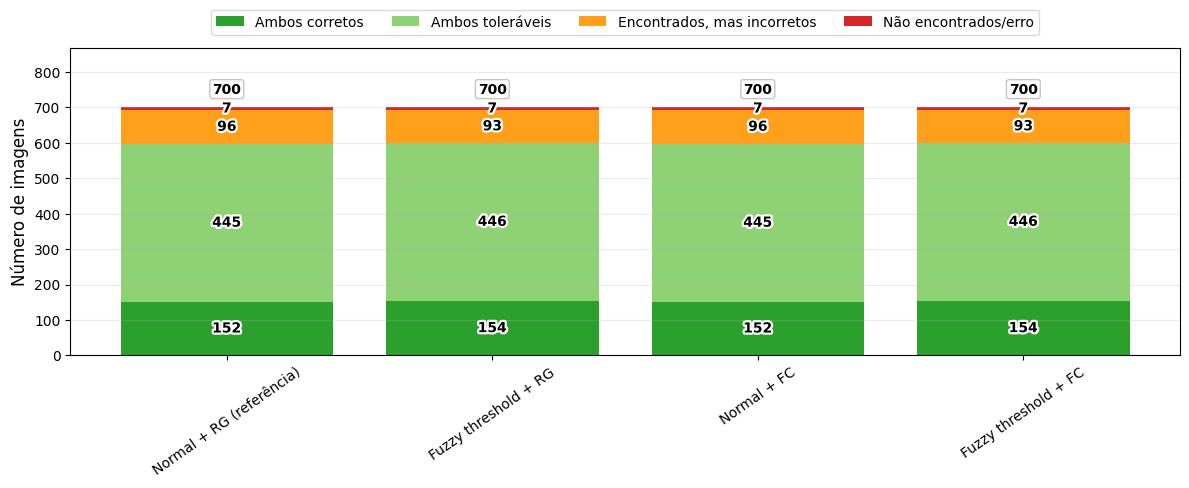

In [6]:
plot_ostia_status_by_variant(
    summary_df,
    preferred_order=PREFERRED_ORDER,
    pretty_names=PRETTY_NAMES,
    save_path=None,
)
plt.show()

## Dice Score por Variante

A tabela abaixo resume o Dice arterial por variante. O gráfico em seguida mostra média e mediana para comparação visual.

In [7]:
dice_plot = summary_df.copy()
dice_plot["variant_label"] = pd.Categorical(
    dice_plot["variant_label"],
    [PRETTY_NAMES.get(name, name) for name in PREFERRED_ORDER],
    ordered=True,
)
dice_plot = dice_plot.sort_values("variant_label")

In [8]:
dice_stats_df = build_dice_stats_by_variant(results_df, PREFERRED_ORDER)

display(
    dice_stats_df.round(
        {
            "mean_dice": 4,
            "max_dice": 4,
            "min_dice": 4,
            "std_dice": 4,
            "median_dice": 4,
        }
    )
)

,folder_variant,variant_label,mean_dice,max_dice,min_dice,std_dice,median_dice
0,normal_rg,Normal + RG (referência),0.5996,0.7973,0.0,0.1844,0.6677
1,fuzzy_threshold_rg,Fuzzy threshold + RG,0.5988,0.7974,0.0,0.1882,0.6679
2,normal_threshold_fc,Normal + FC,0.5851,0.7917,0.0,0.1867,0.6534
3,fuzzy_threshold_fc,Fuzzy threshold + FC,0.5829,0.7918,0.0,0.1902,0.6522


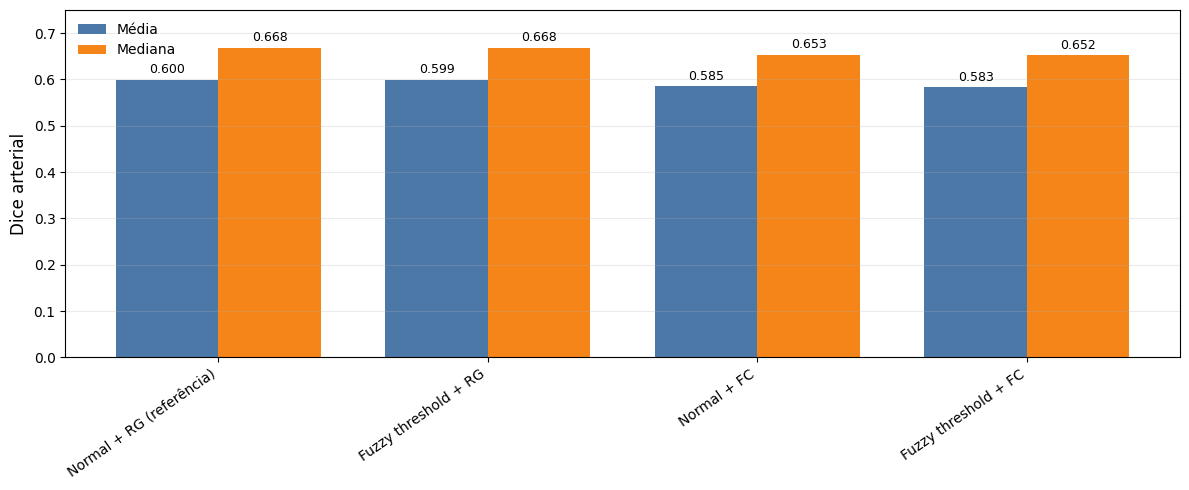

In [9]:
x = np.arange(len(dice_plot))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5))
mean_bars = ax.bar(
    x - width / 2, dice_plot["mean_dice"], width, label="Média", color="#4c78a8"
)
median_bars = ax.bar(
    x + width / 2, dice_plot["median_dice"], width, label="Mediana", color="#f58518"
)

for bars in [mean_bars, median_bars]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.008,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

ax.set_xticks(x)
ax.set_xticklabels(dice_plot["variant_label"].astype(str), rotation=35, ha="right")
ax.set_ylabel("Dice arterial", fontsize=12)
y_max = max(0.75, float(dice_plot[["mean_dice", "median_dice"]].max().max()) + 0.08)
ax.set_ylim(0, y_max)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Melhor variante versus baseline

A melhor variante é escolhida pelo maior Dice médio entre as alternativas. A
comparação pareada usa `Normal + RG` como baseline e somente IDs presentes nos
dois resultados. O delta é calculado como `melhor variante - baseline`.

In [10]:
baseline_variant = "normal_rg"
alternative_summary = summary_df.loc[
    summary_df["folder_variant"].astype(str) != baseline_variant
].copy()
BEST_COMPARISON_VARIANT = str(
    alternative_summary.sort_values("mean_dice", ascending=False).iloc[0][
        "folder_variant"
    ]
)

best_vs_baseline_df = build_delta_summary_vs_reference(
    results_df,
    baseline_variant,
    variants=[BEST_COMPARISON_VARIANT],
    pretty_names=PRETTY_NAMES,
)

print(f"Baseline: {PRETTY_NAMES[baseline_variant]}")
print(
    "Melhor variante: "
    f"{PRETTY_NAMES.get(BEST_COMPARISON_VARIANT, BEST_COMPARISON_VARIANT)}"
)
display(
    best_vs_baseline_df.round(
        {
            "mean_delta": 4,
            "median_delta": 4,
            "max_gain": 4,
            "max_loss": 4,
        }
    )
)

Baseline: Normal + RG (referência)
Melhor variante: Fuzzy threshold + RG


,folder_variant,variant_label,mean_delta,median_delta,variant_better_by_0_02_n,reference_better_by_0_02_n,max_gain,max_loss
0,fuzzy_threshold_rg,Fuzzy threshold + RG,-0.0008,0.0,14,12,0.7404,-0.6386


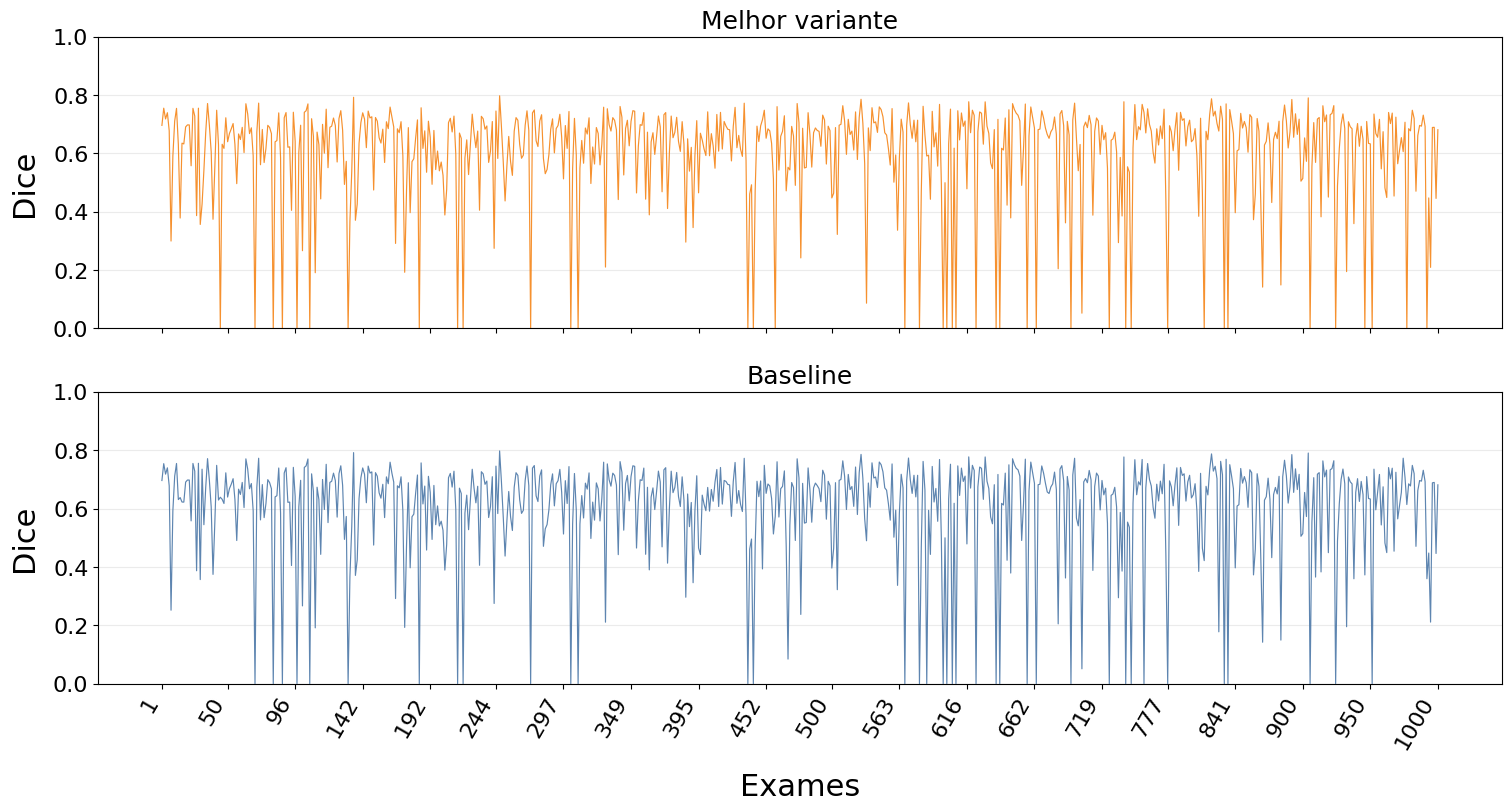

In [11]:
DICE_PANEL_NAMES = {
    baseline_variant: "Baseline",
    BEST_COMPARISON_VARIANT: "Melhor variante",
}
plot_pair_dice_by_image(
    results_df,
    baseline_variant,
    BEST_COMPARISON_VARIANT,
    pretty_names=DICE_PANEL_NAMES,
    save_path=None,
)
plt.show()

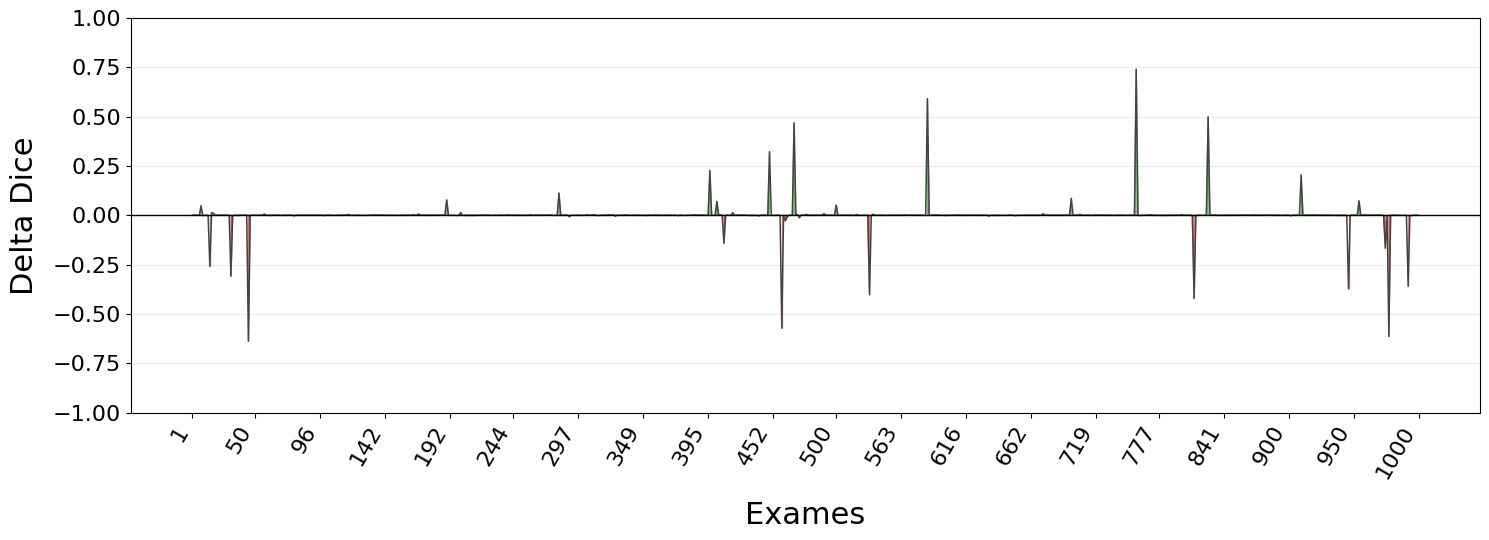

In [12]:
plot_pair_delta_by_image(
    results_df,
    baseline_variant,
    BEST_COMPARISON_VARIANT,
    pretty_names=PRETTY_NAMES,
    save_path=None,
)
plt.show()

## Comparações estatísticas pareadas

Wilcoxon bilateral contra normal+RG, com Holm para as três alternativas no
conjunto selecionado. O efeito é rank-biserial: positivo favorece a alternativa.
O IC95% da diferença média usa bootstrap pareado (10.000 amostras, seed 42).
O teste avalia ranks e o IC avalia a média; suas conclusões podem diferir.


In [13]:
# Mantém todos os IDs, incluindo as falhas registradas como Dice zero.
baseline_df = results_df.loc[results_df["folder_variant"].eq("normal_rg")]
statistic_rows = []
for variant in PREFERRED_ORDER[1:]:
    candidate_df = results_df.loc[results_df["folder_variant"].eq(variant)]
    statistic_rows.append(
        {"variant": variant, **compare_paired_dice(baseline_df, candidate_df)}
    )
paired_statistics_df = pd.DataFrame(statistic_rows)
paired_statistics_df["p_holm"] = adjust_holm(paired_statistics_df["p_value"])
display(
    paired_statistics_df[
        [
            "variant", "paired_images", "mean_delta_dice", "wilcoxon_statistic",
            "p_value", "p_holm", "rank_biserial_effect",
            "mean_delta_ci_95_low", "mean_delta_ci_95_high",
        ]
    ]
)


,variant,paired_images,mean_delta_dice,wilcoxon_statistic,p_value,p_holm,rank_biserial_effect,mean_delta_ci_95_low,mean_delta_ci_95_high
0,fuzzy_threshold_rg,700,-0.000836,19024.0,5.857339e-05,5.857339e-05,0.259190,-0.006095,0.004450
1,normal_threshold_fc,700,-0.014519,63486.0,1.555155e-21,4.665464e-21,-0.426621,-0.019386,-0.009636
2,fuzzy_threshold_fc,700,-0.016695,66170.0,1.618814e-19,3.237628e-19,-0.404172,-0.023842,-0.009443
